# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

### Execution notes
This version uses the supplied `Lab_11_QnA_Dataset.csv`. The Colab-only upload import was removed. The Keras tokenizer runs with the PyTorch backend. The RNN uses `batch_first=True`, gradients are cleared before each update, and padding is excluded from attention. Training retains the original 50 epochs and learning rate. Orange bars identify the maximum attention weight. Attention applies to contextual RNN hidden states, so a highlighted word is not an isolated explanation of the prediction.

## Step 1 — Import libraries

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

torch.manual_seed(42)
torch.set_num_threads(1)

## Step 2 — Upload the dataset

In [2]:
from pathlib import Path
dataset_path = Path("Lab_11_QnA_Dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("/content/Lab_11_QnA_Dataset.csv")
df = pd.read_csv(dataset_path)
assert not df[["question", "answer_id", "answer"]].isna().any().any()
assert sorted(df.answer_id.unique()) == list(range(df.answer_id.nunique()))
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from keras.src.legacy.preprocessing.text import Tokenizer
from keras.utils import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        # X is [batch, sequence], so the RNN must be batch-first.
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = x.ne(0)
        hidden, _ = self.rnn(self.emb(x))
        # Padding is not a word and must receive zero attention.
        scores = self.att(hidden).squeeze(-1).masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
loss_history = []
for epoch in range(50):
    optimizer.zero_grad()  # Start each update with fresh gradients.
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:2d}/50 | loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    logits, attention = model(X)
    training_accuracy = (logits.argmax(1) == y).float().mean().item()
    assert torch.allclose(attention.sum(1), torch.ones(len(X)), atol=1e-6)
    assert torch.all(attention[X == 0] == 0)
    # A question's result must not depend on other examples in its batch.
    single_logits, _ = model(X[:1])
    assert torch.allclose(single_logits, logits[:1], atol=1e-5)
print(f"Training finished! Training accuracy: {training_accuracy:.1%}")
print("Training-set accuracy only; no held-out generalization estimate.")

Epoch 10/50 | loss = 1.9305
Epoch 20/50 | loss = 1.2049
Epoch 30/50 | loss = 0.5520
Epoch 40/50 | loss = 0.1980
Epoch 50/50 | loss = 0.0688
Training finished! Training accuracy: 98.8%
Training-set accuracy only; no held-out generalization estimate.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

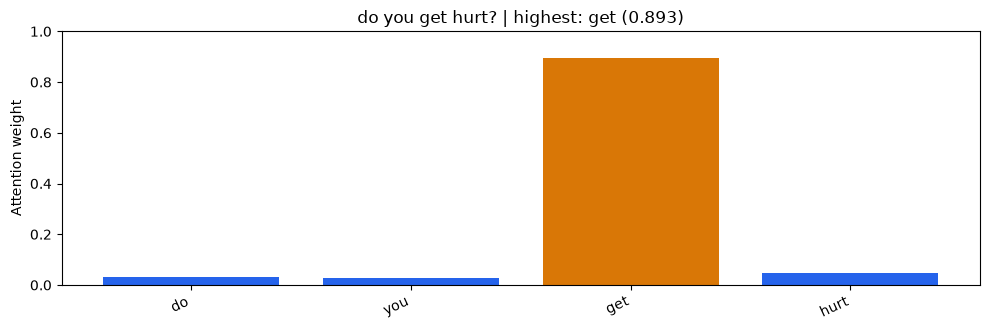

,question,highest_attention_word,weight,predicted_answer_id,actual_answer_id
0,do you get hurt?,get,0.893149,0,0


In [6]:
def show_attention(indices, filename):
    model.eval()
    with torch.no_grad():
        logits, weights = model(X[indices])
    fig, axes = plt.subplots(len(indices), 1, figsize=(10, 3.4 * len(indices)), squeeze=False)
    rows = []
    for ax, index, prediction, weight in zip(axes[:, 0], indices, logits.argmax(1), weights):
        token_ids = X[index][X[index] != 0].tolist()
        words = [tokenizer.index_word[token] for token in token_ids]
        values = weight[:len(words)].tolist()
        top = max(range(len(values)), key=values.__getitem__)
        colors = ["#d97706" if j == top else "#2563eb" for j in range(len(words))]
        ax.bar(range(len(words)), values, color=colors)
        ax.set_xticks(range(len(words)), words, rotation=25, ha="right")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Attention weight")
        ax.set_title(f'{df.loc[index, "question"]} | highest: {words[top]} ({values[top]:.3f})')
        rows.append({"question": df.loc[index, "question"], "highest_attention_word": words[top],
                     "weight": values[top], "predicted_answer_id": int(prediction),
                     "actual_answer_id": int(y[index])})
    fig.tight_layout()
    fig.savefig(filename, dpi=160, bbox_inches="tight")
    plt.show()
    result = pd.DataFrame(rows)
    display(result)
    return result

show_attention([0], "step6_attention.png");

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

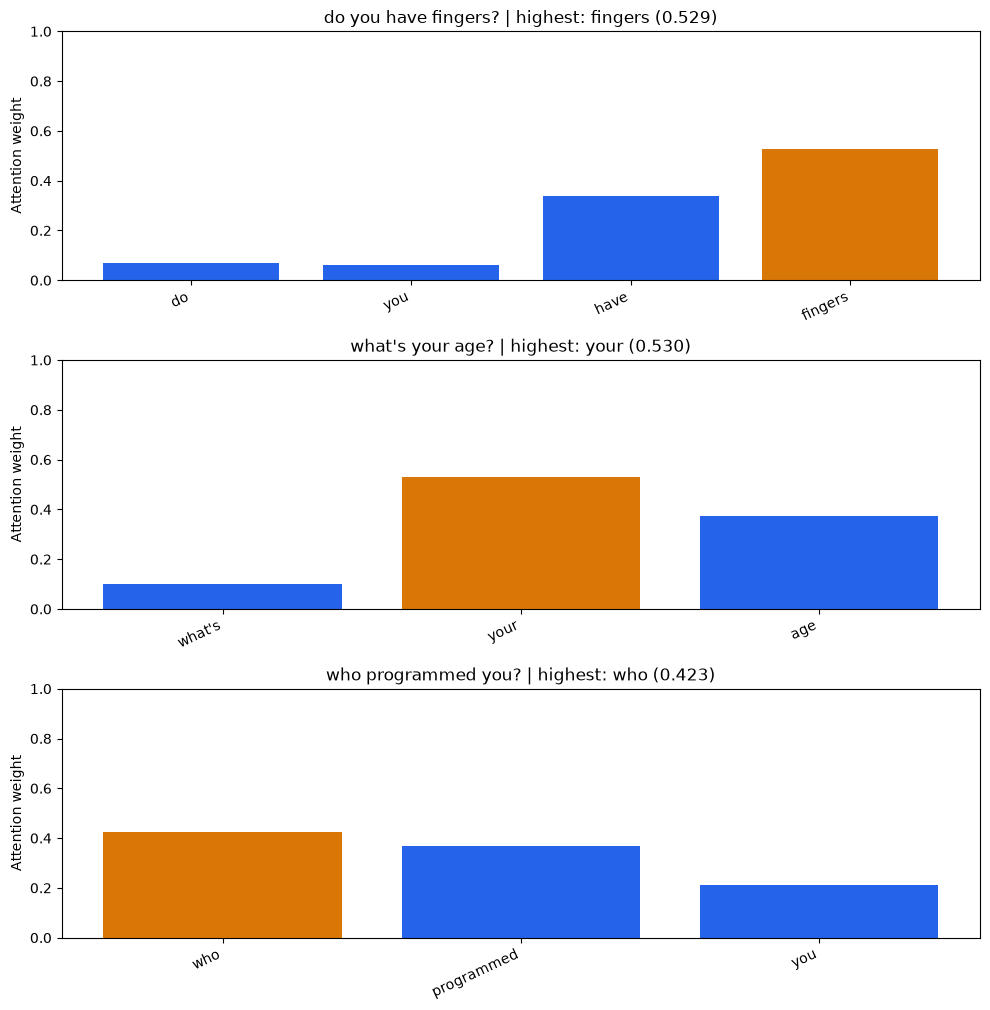

,question,highest_attention_word,weight,predicted_answer_id,actual_answer_id
0,do you have fingers?,fingers,0.529017,0,0
1,what's your age?,your,0.529511,1,1
2,who programmed you?,who,0.422566,3,3


In [7]:
# Three questions from different answer groups.
task1_questions = ["do you have fingers?", "what's your age?", "who programmed you?"]
task1_indices = [df.index[df.question.eq(q)][0] for q in task1_questions]
task1_results = show_attention(task1_indices, "task1_attention.png")

### Task 1 — Observations

| Question | Highest-attention word | Weight |
| --- | --- | --- |
| do you have fingers? | **fingers** | 0.529 |
| what's your age? | **your** | 0.530 |
| who programmed you? | **who** | 0.423 |

**Do these words appear important?** Sometimes. `fingers` directly identifies the topic of the first question and is an informative word. `your` receives the highest weight in the age question, even though `age` carries the clearest topic information. `who` helps identify a question about a person or creator, but `programmed` is needed to distinguish creation from other questions beginning with `who`.

The three selected questions are classified correctly, but attention does not always match human judgments of word importance. The model learns weights that help its answer-classification objective on this small dataset. Each weight applies to an RNN hidden state that includes the current word and preceding context, rather than an isolated word embedding. These plots describe learned attention; they do not prove a word caused the answer.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

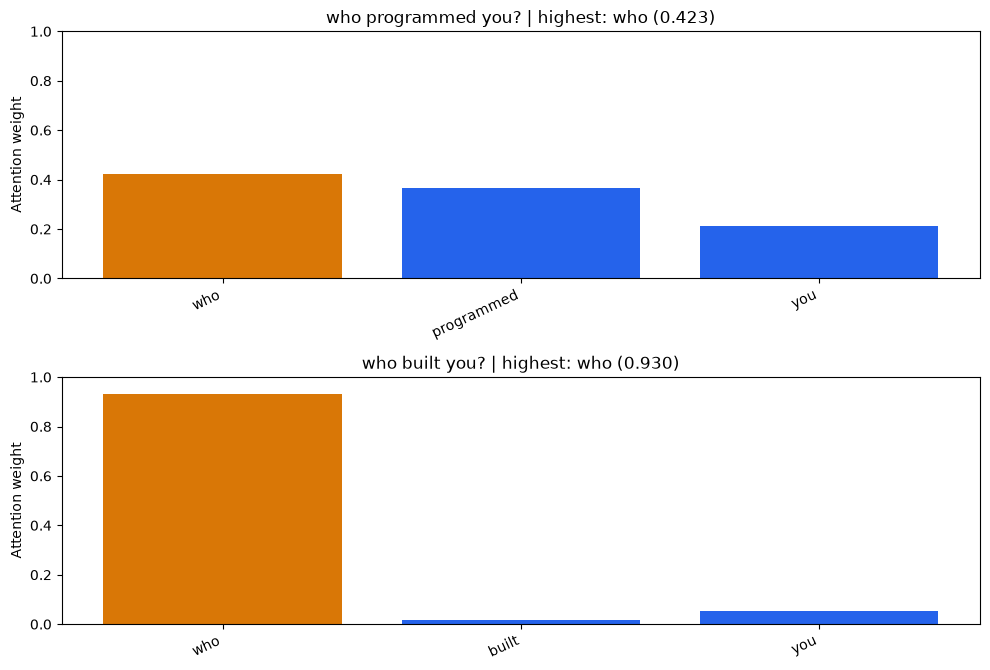

,question,highest_attention_word,weight,predicted_answer_id,actual_answer_id
0,who programmed you?,who,0.422566,3,3
1,who built you?,who,0.929510,3,3


1092

In [8]:
# Both questions ask about the bot's creator, using different verbs.
task2_questions = ["who programmed you?", "who built you?"]
task2_indices = [df.index[df.question.eq(q)][0] for q in task2_questions]
assert df.loc[task2_indices, "answer_id"].nunique() == 1
task2_results = show_attention(task2_indices, "task2_attention.png")

# Save measured results for the written discussion.
import json
from pathlib import Path
Path("attention_results.json").write_text(json.dumps({
    "training_accuracy": training_accuracy,
    "loss_start": loss_history[0], "loss_end": loss_history[-1],
    "task1": task1_results.to_dict("records"),
    "task2": task2_results.to_dict("records")}, indent=2), encoding="utf-8")

### Task 2 — Comparison and explanation

Both **“who programmed you?”** and **“who built you?”** ask who created the bot and have answer group 3: *People created me.* The trained model predicts group 3 for both.

The highest-attention word is **`who`** in the first question (weight **0.423**) and **`who`** in the second (weight **0.930**). Thus, the model focuses most strongly on the same word, but attention is much more concentrated in the second question. The distributions are not identical despite the similar meanings.

This suggests that attention can emphasize a shared cue across paraphrases while assigning different weights according to the wording and learned hidden states. It does not guarantee that synonymous verbs such as `programmed` and `built` will receive the highest weights. The shared focus on `who` alone is insufficient to establish semantic understanding because other answer groups also contain `who` questions.

**Evaluation scope:** the model was trained for 50 epochs on all 168 questions across 12 answer groups. Training accuracy is **98.81%**, with loss decreasing from **2.5131** to **0.0688**. These examples come from the training data; no held-out accuracy was measured.